
  SDAE DETERMINISTIC BCI MASTER RIG - EXECUTION MODE
  [1] Run live BCI experiment / Benchmark R with Unity (Default)
  [2] Skip live trials & generate plots from existing CSV data


[SDAE Python Master] Waiting for Unity PLAY trigger (or press Key R in Unity for 10-trial Benchmark)...

[SESSION STARTED] Subject: #2 | Mode: TRAINING
                  Trials: 20 | Unified CSV: bci_sessions\Subject_02_TRAINING_20261113_084247.csv

---> [Trial #1/20] Target: LEFT | Spd: 80% | Trig: 50%
     [OK] Py: 3750.00ms (Jit ±0.003ms) | Unity: 3750.02ms (IPC 594.0µs, DecTrans 345.5µs, Margin +19.17ms, GPU 53fps)

[NOTICE] Key R detected -> Aborting standard batch to launch Benchmark R...
[SDAE Python Master] Waiting for Unity PLAY trigger (or press Key R in Unity for 10-trial Benchmark)...

[SESSION STARTED] Subject: #2 | Mode: BENCHMARK_R
                  Trials: 10 | Unified CSV: bci_sessions\Subject_02_BENCHMARK_R_20261113_084254.csv

---> [Trial #1/10] Target: LEFT | Spd: 85% | Trig: 21%
     [OK] Py: 3529.00ms (Jit ±0.003ms) | Unity: 3529.00ms (IPC 850.4µs, DecTrans 877.0µs, Margin +19.09ms, GPU 46fps)
---> [Trial #2/10] Target: RIGHT | Spd: 19% | Trig: 47%
     [OK] Py: 1

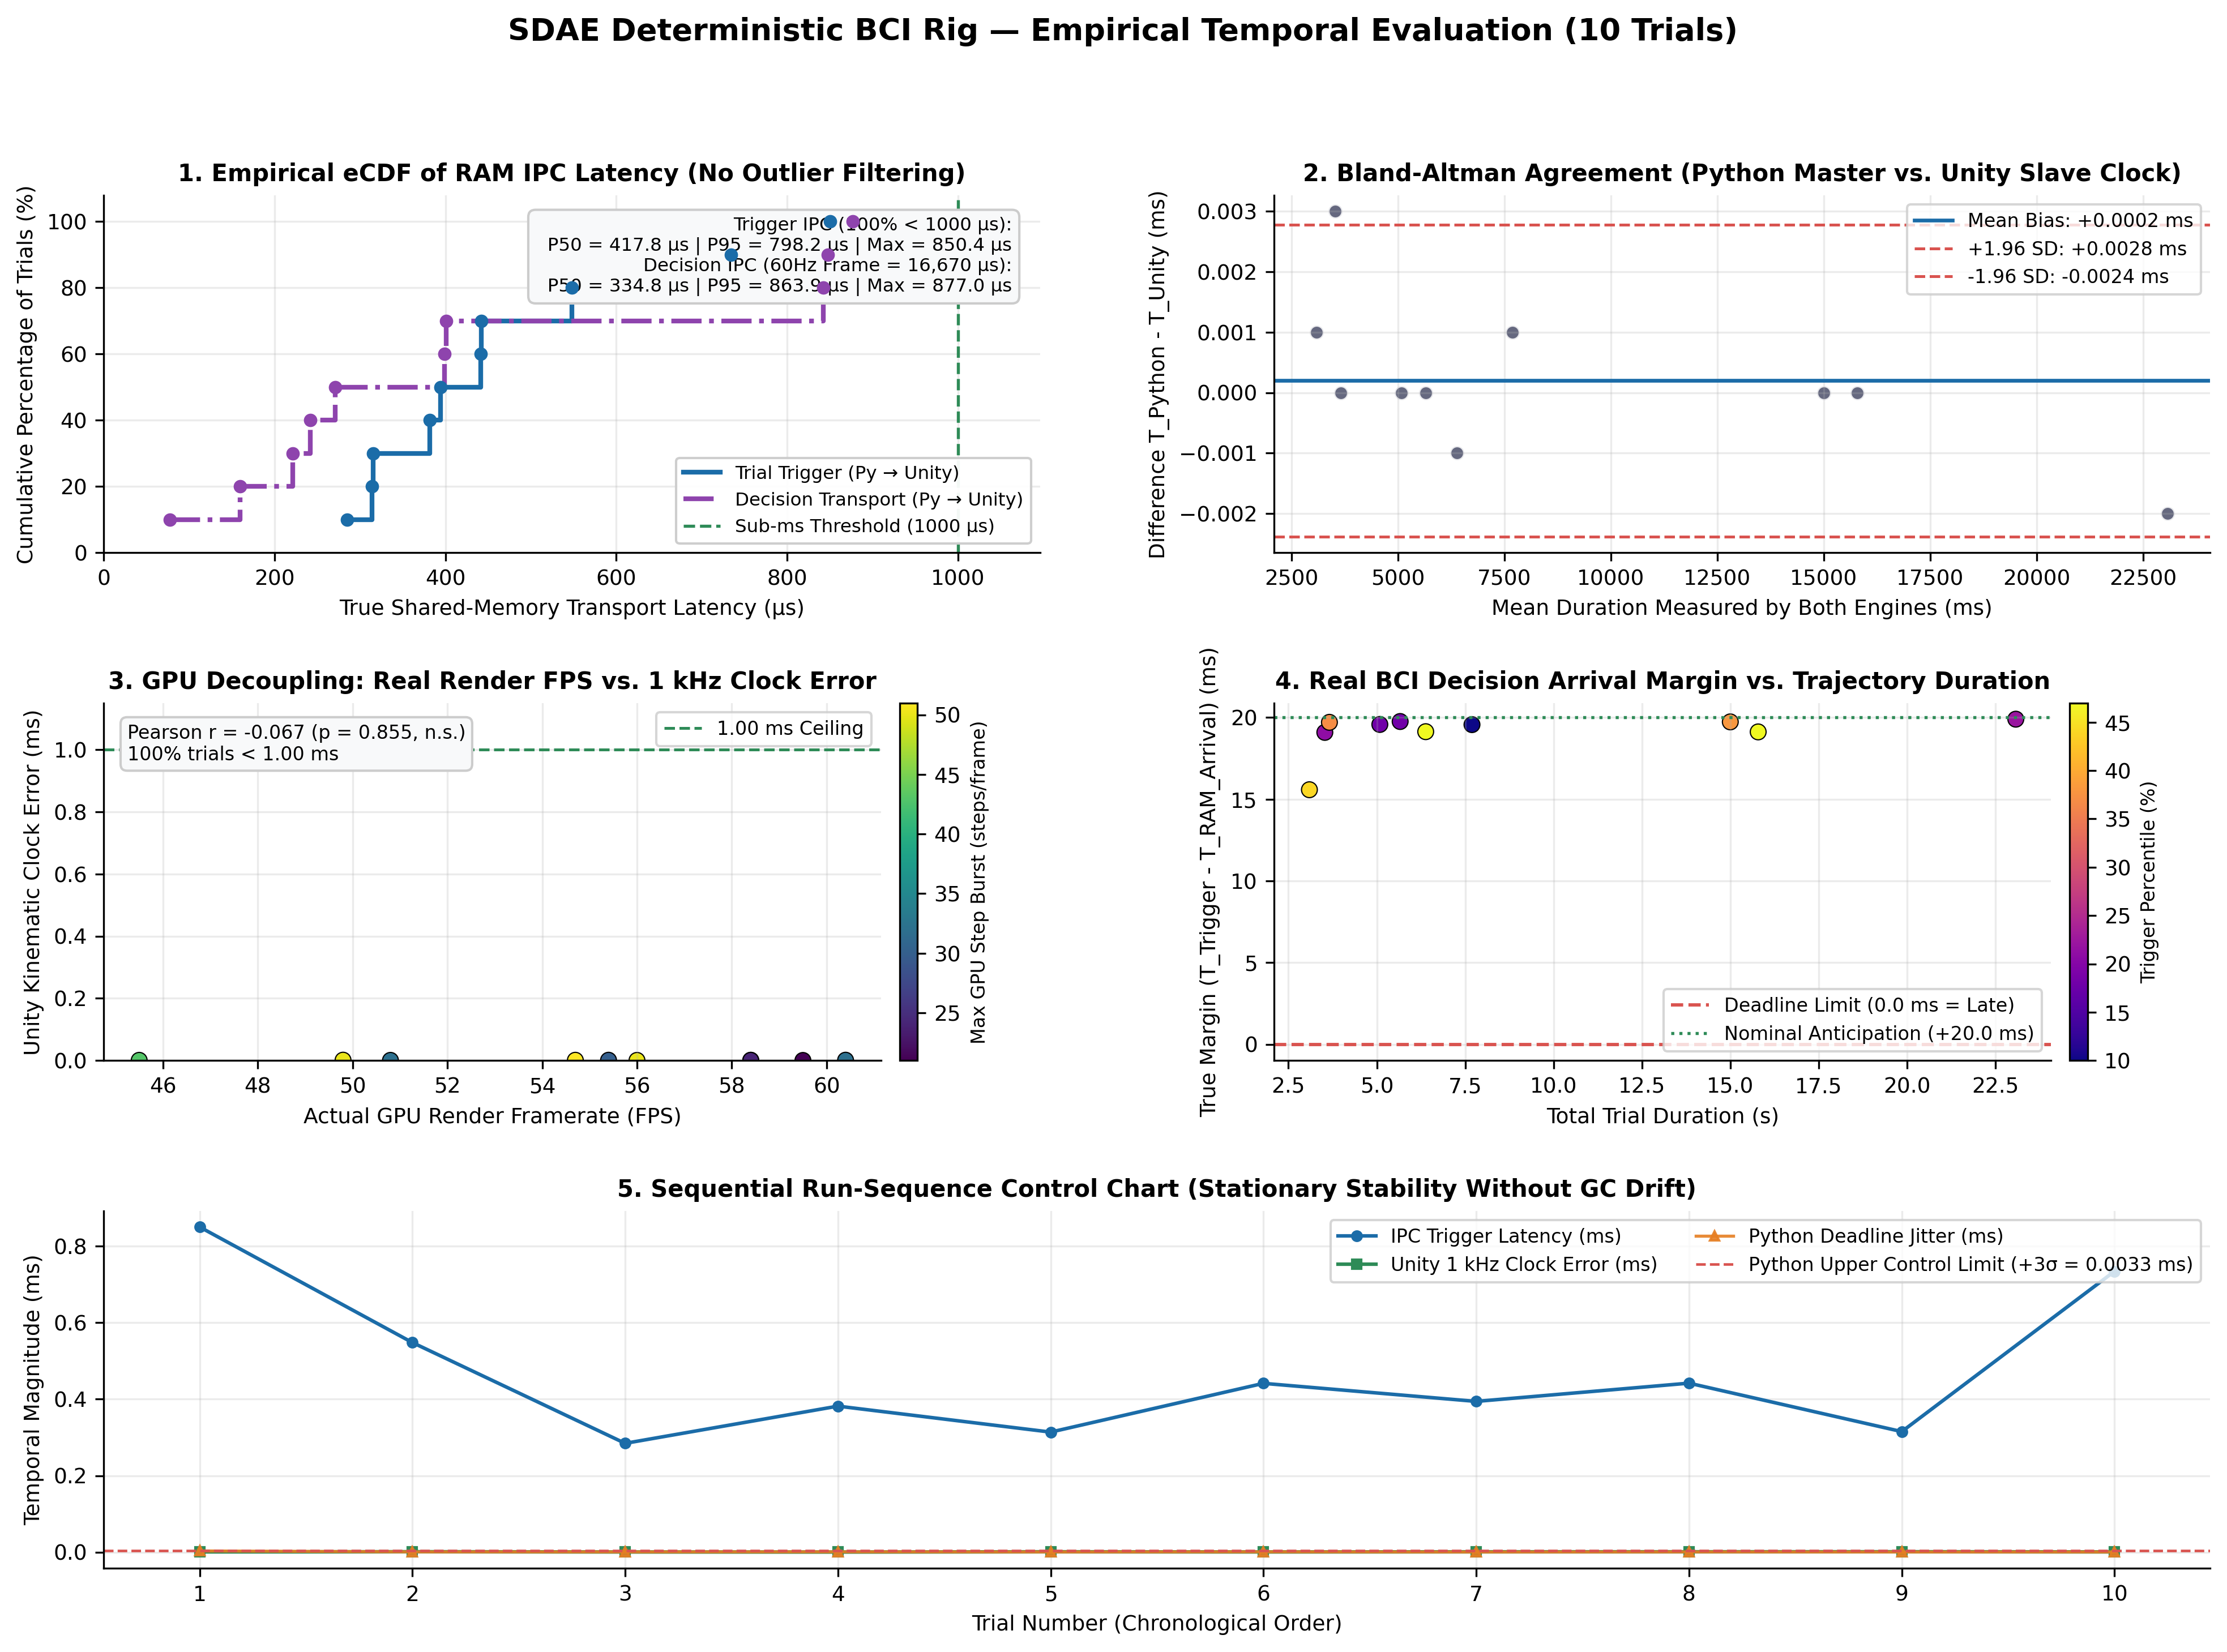

In [ ]:

import gc
import os
import sys
import csv
import glob
import math
import time
import mmap
import struct
import ctypes
import random
import argparse
from datetime import datetime

import numpy as np
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

# =========================================================================
# WINDOWS REAL-TIME SCHEDULER & CPU AFFINITY CONFIGURATION (64-BIT SAFE)
# =========================================================================
if os.name == "nt":
    winmm = ctypes.WinDLL('winmm')
    kernel32 = ctypes.WinDLL('kernel32')

    kernel32.GetCurrentProcess.restype = ctypes.c_void_p
    kernel32.GetCurrentThread.restype = ctypes.c_void_p
    kernel32.SetPriorityClass.argtypes = [ctypes.c_void_p, ctypes.c_uint32]
    kernel32.SetThreadPriority.argtypes = [ctypes.c_void_p, ctypes.c_int]
    kernel32.SetProcessAffinityMask.argtypes = [ctypes.c_void_p, ctypes.c_size_t]

HIGH_PRIORITY_CLASS = 0x00000080
THREAD_PRIORITY_HIGHEST = 2


def configure_realtime_windows_process() -> None:
    """Locks Windows multimedia timer to 1 ms, elevates priority, and isolates Python on the last CPU core."""
    if os.name != "nt":
        return
    winmm.timeBeginPeriod(1)
    proc_handle = kernel32.GetCurrentProcess()
    thread_handle = kernel32.GetCurrentThread()

    kernel32.SetPriorityClass(proc_handle, HIGH_PRIORITY_CLASS)
    kernel32.SetThreadPriority(thread_handle, THREAD_PRIORITY_HIGHEST)

    cpu_count = os.cpu_count() or 1
    if cpu_count >= 4:
        dedicated_core_mask = 1 << (cpu_count - 1)
        kernel32.SetProcessAffinityMask(proc_handle, dedicated_core_mask)


def restore_windows_process() -> None:
    """Restores default Windows timer resolution upon exit."""
    if os.name == "nt":
        winmm.timeEndPeriod(1)


# =========================================================================
# 96-BYTE LOCK-FREE SHARED MEMORY MAP ("sdae_bci_memory")
# =========================================================================
# Offset  0 (int32)  : trialId
# Offset  4 (int32)  : groundTruth (1 = Left, 2 = Right)
# Offset  8 (int32)  : totalSteps
# Offset 12 (int32)  : decisionDeadlineStep
# Offset 16 (int32)  : unityState (0=Standby, 1=PreparingHands, 2=Falling, 3=Done)
# Offset 20 (int32)  : decision (1 = Left, 2 = Right)
# Offset 24 (int64)  : pythonTriggerTimestampNs
# Offset 32 (int32)  : subjectNumber
# Offset 36 (int32)  : trainingMode (1 = Training, 0 = Testing)
# Offset 40 (float32): speedPercentage
# Offset 44 (float32): decisionPercentile
# Offset 48 (int32)  : unityConfigReady
# Offset 52 (int32)  : benchmarkActive (Key R)
# Offset 56 (float32): unityIpcTriggerLatencyMs
# Offset 60 (float32): unityDecisionTransportLatencyMs
# Offset 64 (float32): unityActualKinematicMs
# Offset 68 (float32): unityClockJitterMs
# Offset 72 (int32)  : unityMaxFrameStepBurst
# Offset 76 (float32): unityMeanTrialFps
# Offset 80 (int64)  : pythonDecisionTimestampNs
# Offset 88 (float32): unityAnticipationMarginMs
PAYLOAD_SIZE = 96
STEP_DURATION_NS = 1_000_000  # 1.00 ms per step (1 kHz)


def get_shared_memory() -> mmap.mmap:
    """Opens or creates the 96-byte named RAM shared-memory block."""
    return mmap.mmap(-1, PAYLOAD_SIZE, "sdae_bci_memory", access=mmap.ACCESS_WRITE)


def is_unity_active(mm: mmap.mmap) -> bool:
    """Returns True while Unity's experimental scene holds unityConfigReady == 1."""
    mm.seek(48)
    return struct.unpack('<i', mm.read(4))[0] == 1


def is_benchmark_requested(mm: mmap.mmap) -> bool:
    """Returns True when Key R has been pressed in Unity (benchmarkActive == 1)."""
    mm.seek(52)
    return struct.unpack('<i', mm.read(4))[0] == 1


def wait_for_unity_menu_config(mm: mmap.mmap) -> dict:
    """Blocks until Unity publishes initial session parameters from Menu.cs."""
    print("[SDAE Python Master] Waiting for Unity PLAY trigger (or press Key R in Unity for 10-trial Benchmark)...")
    while True:
        if is_unity_active(mm):
            mm.seek(8)
            total_steps, deadline_step = struct.unpack('<ii', mm.read(8))
            mm.seek(32)
            subject_num, training_flag, speed_pct, trigger_pct = struct.unpack('<iiff', mm.read(16))

            if total_steps > 0 and deadline_step > 0:
                return {
                    "subject": subject_num,
                    "training": bool(training_flag),
                    "mode": "TRAINING" if training_flag == 1 else "TESTING",
                    "total_steps": total_steps,
                    "deadline_step": deadline_step,
                    "speed_pct": speed_pct,
                    "trigger_pct": trigger_pct
                }
        time.sleep(0.02)


def generate_balanced_trials(total_trials: int, randomize: bool = True) -> list[int]:
    """Generates a class-balanced sequence of Left (1) and Right (2) trials."""
    half = total_trials // 2
    trials = [1] * half + [2] * (total_trials - half)
    if randomize:
        random.shuffle(trials)
    return trials


def run_bci_inference(ground_truth: int, is_training: bool, trial_num: int) -> int:
    """
    Executes BCI classification at the trial's deadline step.
    In TRAINING mode, returns ground truth for motor-imagery calibration.
    In TESTING mode, replace the fallback return with your online EEG classifier output.
    """
    if is_training:
        return ground_truth
    # TODO: Integrate real-time EEG feature extraction & classifier prediction here
    return ground_truth


def _parse_cell(val: str):
    """Parses numeric CSV fields to float while preserving string labels."""
    if val is None:
        return 0.0
    try:
        return float(val)
    except ValueError:
        return val.strip()


def _betacf(a: float, b: float, x: float) -> float:
    """Evaluates continued fraction for incomplete beta function (exact two-tailed p-value)."""
    max_iter = 200
    eps = 3.0e-12
    fpmin = 1.0e-30
    qab = a + b
    qap = a + 1.0
    qam = a - 1.0
    c = 1.0
    d = 1.0 - qab * x / qap
    if abs(d) < fpmin:
        d = fpmin
    d = 1.0 / d
    h = d
    for m in range(1, max_iter + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin:
            d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin:
            c = fpmin
        d = 1.0 / d
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin:
            d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin:
            c = fpmin
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < eps:
            break
    return h


def _pearson_r_and_p(x: np.ndarray, y: np.ndarray) -> tuple[float, float]:
    """Computes Pearson correlation coefficient r and exact two-tailed p-value."""
    n = len(x)
    if n < 3 or np.std(x) <= 1e-9 or np.std(y) <= 1e-9:
        return 0.0, 1.0
    r = float(np.corrcoef(x, y)[0, 1])
    r = max(-0.999999, min(0.999999, r))
    df = n - 2
    t_stat = abs(r) * math.sqrt(df / (1.0 - r * r))
    x_beta = df / (df + t_stat * t_stat)
    a = 0.5 * df
    b = 0.5
    bt = math.exp(
        math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
        + a * math.log(x_beta) + b * math.log(1.0 - x_beta)
    )
    if x_beta < (a + 1.0) / (a + b + 2.0):
        ibeta = bt * _betacf(a, b, x_beta) / a
    else:
        ibeta = 1.0 - bt * _betacf(b, a, 1.0 - x_beta) / b
    return r, max(0.0, min(1.0, ibeta))


def _display_chart_immediately(png_path: str) -> None:
    """Renders the output PNG inline in interactive consoles and opens the native OS viewer."""
    abs_png = os.path.abspath(png_path)
    if "ipykernel" in sys.modules:
        try:
            from IPython.display import display, Image
            display(Image(filename=abs_png))
        except Exception:
            pass
    if os.name == "nt":
        try:
            os.startfile(abs_png)
        except Exception:
            pass


def generate_academic_performance_plots(csv_path: str) -> None:
    """
    Generates and displays 5 publication-grade empirical evaluation figures (300 DPI PNG + PDF):
    1. Empirical eCDF of Shared-Memory IPC Latency in Microseconds (µs) with P50, P95, Max.
    2. Bland-Altman Agreement Plot (Python Master Clock vs. Unity 1 kHz Slave Clock).
    3. GPU Decoupling Analysis (Actual Render FPS & Step Bursts vs. 1 kHz Clock Error with Pearson r & p).
    4. True BCI Decision Anticipation Margin vs. Trajectory Duration.
    5. Sequential Run-Sequence Control Chart (+/- 3 Sigma Stationary Stability).
    """
    if not os.path.exists(csv_path):
        print(f"[Plots Error] CSV file not found: {csv_path}")
        return

    rows = []
    with open(csv_path, mode="r", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        for r in reader:
            if not r:
                continue
            rows.append({k.strip(): _parse_cell(v) for k, v in r.items() if k is not None})

    if len(rows) < 2:
        print("[Plots] At least 2 recorded trials are required to compute statistical plots.")
        return

    trials = np.array([r["trial_id"] for r in rows], dtype=float)
    trigger_pct = np.array([r["trigger_pct"] for r in rows], dtype=float)
    py_dur = np.array([r["py_fall_duration_ms"] for r in rows], dtype=float)
    py_jitter = np.array([r["py_max_step_jitter_ms"] for r in rows], dtype=float)
    u_ipc_trig_us = np.array([r["u_ipc_trigger_latency_ms"] for r in rows], dtype=float) * 1000.0
    u_dec_trans_us = np.array([r["u_decision_transport_ms"] for r in rows], dtype=float) * 1000.0
    u_ant_margin = np.array([r["u_anticipation_margin_ms"] for r in rows], dtype=float)
    u_dur = np.array([r["u_actual_kinematic_ms"] for r in rows], dtype=float)
    u_jitter = np.array([r["u_clock_jitter_ms"] for r in rows], dtype=float)
    u_burst = np.array([r["u_max_frame_burst"] for r in rows], dtype=float)
    u_fps = np.array([r["u_mean_fps"] for r in rows], dtype=float)
    theo_dur = np.array([r["total_steps"] for r in rows], dtype=float)

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False
    })

    fig = plt.figure(figsize=(16, 10.5), dpi=300)
    gs = fig.add_gridspec(3, 2, hspace=0.42, wspace=0.25)

    # -------------------------------------------------------------------------
    # FIGURE 1: Empirical eCDF of RAM IPC Latency (µs)
    # -------------------------------------------------------------------------
    ax1 = fig.add_subplot(gs[0, 0])
    sorted_trig = np.sort(u_ipc_trig_us)
    sorted_dec = np.sort(u_dec_trans_us)
    ecdf_y = np.arange(1, len(sorted_trig) + 1) / len(sorted_trig) * 100.0

    p50_t, p95_t, pmax_t = np.percentile(u_ipc_trig_us, [50, 95, 100])
    p50_d, p95_d, pmax_d = np.percentile(u_dec_trans_us, [50, 95, 100])

    ax1.step(sorted_trig, ecdf_y, where="post", color="#1b6ca8", linewidth=2.0, label="Trial Trigger (Py → Unity)")
    ax1.scatter(sorted_trig, ecdf_y, color="#1b6ca8", s=22, zorder=4)
    ax1.step(sorted_dec, ecdf_y, where="post", color="#8e44ad", linewidth=2.0, linestyle="-.", label="Decision Transport (Py → Unity)")
    ax1.scatter(sorted_dec, ecdf_y, color="#8e44ad", s=22, zorder=4)

    max_obs_us = max(pmax_t, pmax_d)
    x_upper = max(25.0, max_obs_us * 1.25)
    if x_upper >= 1000.0:
        ax1.axvline(1000.0, color="#2e8b57", linestyle="--", linewidth=1.3, label="Sub-ms Threshold (1000 µs)")

    stats_txt = (
        f"Trigger IPC (100% < 1000 µs):\n  P50 = {p50_t:.1f} µs | P95 = {p95_t:.1f} µs | Max = {pmax_t:.1f} µs\n"
        f"Decision IPC (60Hz Frame = 16,670 µs):\n  P50 = {p50_d:.1f} µs | P95 = {p95_d:.1f} µs | Max = {pmax_d:.1f} µs"
    )
    ax1.text(0.97, 0.94, stats_txt, transform=ax1.transAxes, ha="right", va="top", fontsize=7.8,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="#f8f9fa", edgecolor="#cccccc"))
    ax1.set_title("1. Empirical eCDF of RAM IPC Latency (No Outlier Filtering)")
    ax1.set_xlabel("True Shared-Memory Transport Latency (µs)")
    ax1.set_ylabel("Cumulative Percentage of Trials (%)")
    ax1.set_xlim(left=0.0, right=x_upper)
    ax1.set_ylim(0, 108)
    ax1.legend(loc="lower right", fontsize=7.8, framealpha=0.95)

    # -------------------------------------------------------------------------
    # FIGURE 2: Bland-Altman Agreement Plot (Python vs. Unity Clock)
    # -------------------------------------------------------------------------
    ax2 = fig.add_subplot(gs[0, 1])
    mean_duals = 0.5 * (py_dur + u_dur)
    diff_duals = py_dur - u_dur
    bias = np.mean(diff_duals)
    sd_diff = np.std(diff_duals, ddof=1) if len(diff_duals) > 1 else 0.0
    loa_upper = bias + 1.96 * sd_diff
    loa_lower = bias - 1.96 * sd_diff

    ax2.scatter(mean_duals, diff_duals, color="#4a4e69", alpha=0.85, s=36, edgecolor="white")
    ax2.axhline(bias, color="#1b6ca8", linestyle="-", linewidth=1.6, label=f"Mean Bias: {bias:+.4f} ms")
    ax2.axhline(loa_upper, color="#d9534f", linestyle="--", linewidth=1.2, label=f"+1.96 SD: {loa_upper:+.4f} ms")
    ax2.axhline(loa_lower, color="#d9534f", linestyle="--", linewidth=1.2, label=f"-1.96 SD: {loa_lower:+.4f} ms")
    ax2.set_title("2. Bland-Altman Agreement (Python Master vs. Unity Slave Clock)")
    ax2.set_xlabel("Mean Duration Measured by Both Engines (ms)")
    ax2.set_ylabel("Difference T_Python - T_Unity (ms)")
    ax2.legend(loc="best", fontsize=8)

    # -------------------------------------------------------------------------
    # FIGURE 3: GPU Decoupling (Render FPS vs. 1 kHz Clock Error)
    # -------------------------------------------------------------------------
    ax3 = fig.add_subplot(gs[1, 0])
    sc = ax3.scatter(u_fps, u_jitter, c=u_burst, cmap="viridis", s=45, edgecolor="black", linewidth=0.5)
    cbar = plt.colorbar(sc, ax=ax3, pad=0.02)
    cbar.set_label("Max GPU Step Burst (steps/frame)", fontsize=8)

    r_val, p_val = _pearson_r_and_p(u_fps, u_jitter)
    sig_label = "n.s." if p_val >= 0.05 else "p < 0.05"
    pct_sub_ms = np.mean(u_jitter < 1.0) * 100.0

    ax3.axhline(1.0, color="#2e8b57", linestyle="--", linewidth=1.2, label="1.00 ms Ceiling")
    ax3.text(0.03, 0.84, f"Pearson r = {r_val:.3f} (p = {p_val:.3f}, {sig_label})\n{pct_sub_ms:.0f}% trials < 1.00 ms",
             transform=ax3.transAxes, fontsize=8,
             bbox=dict(boxstyle="round,pad=0.35", facecolor="#f8f9fa", edgecolor="#cccccc"))
    ax3.set_title("3. GPU Decoupling: Real Render FPS vs. 1 kHz Clock Error")
    ax3.set_xlabel("Actual GPU Render Framerate (FPS)")
    ax3.set_ylabel("Unity Kinematic Clock Error (ms)")
    ax3.set_ylim(bottom=0.0, top=max(1.15, np.max(u_jitter) * 1.15))
    ax3.legend(loc="upper right", fontsize=8)

    # -------------------------------------------------------------------------
    # FIGURE 4: Real BCI Decision Anticipation Margin vs. Trial Duration
    # -------------------------------------------------------------------------
    ax4 = fig.add_subplot(gs[1, 1])
    sc4 = ax4.scatter(theo_dur / 1000.0, u_ant_margin, c=trigger_pct, cmap="plasma", s=45, edgecolor="black", linewidth=0.5)
    cbar4 = plt.colorbar(sc4, ax=ax4, pad=0.02)
    cbar4.set_label("Trigger Percentile (%)", fontsize=8)
    ax4.axhline(0.0, color="#d9534f", linestyle="--", linewidth=1.4, label="Deadline Limit (0.0 ms = Late)")
    ax4.axhline(20.0, color="#2e8b57", linestyle=":", linewidth=1.3, label="Nominal Anticipation (+20.0 ms)")
    ax4.set_title("4. Real BCI Decision Arrival Margin vs. Trajectory Duration")
    ax4.set_xlabel("Total Trial Duration (s)")
    ax4.set_ylabel("True Margin (T_Trigger - T_RAM_Arrival) (ms)")
    ax4.legend(loc="lower right", fontsize=8)

    # -------------------------------------------------------------------------
    # FIGURE 5: Sequential Run-Sequence Control Chart (+/- 3 Sigma)
    # -------------------------------------------------------------------------
    ax5 = fig.add_subplot(gs[2, :])
    mean_jit = np.mean(py_jitter)
    sd_jit = np.std(py_jitter, ddof=1) if len(py_jitter) > 1 else 0.0

    ax5.plot(trials, u_ipc_trig_us / 1000.0, marker="o", markersize=4, linewidth=1.5, color="#1b6ca8", label="IPC Trigger Latency (ms)")
    ax5.plot(trials, u_jitter, marker="s", markersize=4, linewidth=1.5, color="#2e8b57", label="Unity 1 kHz Clock Error (ms)")
    ax5.plot(trials, py_jitter, marker="^", markersize=4, linewidth=1.3, alpha=0.9, color="#e67e22", label="Python Deadline Jitter (ms)")
    ax5.axhline(mean_jit + 3 * sd_jit, color="#d9534f", linestyle="--", linewidth=1.1, label=f"Python Upper Control Limit (+3σ = {mean_jit + 3*sd_jit:.4f} ms)")
    ax5.set_title("5. Sequential Run-Sequence Control Chart (Stationary Stability Without GC Drift)")
    ax5.set_xlabel("Trial Number (Chronological Order)")
    ax5.set_ylabel("Temporal Magnitude (ms)")
    ax5.set_xticks(trials if len(trials) <= 30 else np.linspace(1, len(trials), 15, dtype=int))
    ax5.legend(loc="upper right", ncol=2, fontsize=8)

    base_name = os.path.splitext(csv_path)[0]
    png_out = f"{base_name}_Academic_Performance.png"
    pdf_out = f"{base_name}_Academic_Performance.pdf"

    fig.suptitle(f"SDAE Deterministic BCI Rig — Empirical Temporal Evaluation ({len(rows)} Trials)", fontsize=13, fontweight="bold", y=0.98)
    fig.savefig(png_out, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_out, bbox_inches="tight")
    plt.close(fig)

    print(f"[Plots] Academic figures exported:\n        -> {png_out}\n        -> {pdf_out}")
    _display_chart_immediately(png_out)


def select_and_plot_existing_csv(csv_path: str | None = None, sessions_dir: str = "bci_sessions") -> None:
    """Allows skipping live trials and generating figures directly from an existing CSV log."""
    if csv_path and os.path.exists(csv_path):
        print(f"[SDAE Plot-Only Mode] Generating plots from specified file: {csv_path}")
        generate_academic_performance_plots(csv_path)
        return

    csv_files = sorted(glob.glob(os.path.join(sessions_dir, "*.csv")), key=os.path.getmtime, reverse=True)
    if not csv_files:
        print(f"[SDAE Plot-Only Mode] No CSV files found in '{sessions_dir}/'. Run live trials first.")
        return

    print("\nAvailable session CSV files (newest first):")
    for idx, path in enumerate(csv_files[:10], start=1):
        print(f"  [{idx}] {path}")

    choice = input("\nSelect file index [Press Enter for #1 latest]: ").strip()
    if choice == "":
        selected_csv = csv_files[0]
    elif choice.isdigit() and 1 <= int(choice) <= min(10, len(csv_files)):
        selected_csv = csv_files[int(choice) - 1]
    else:
        print("[SDAE Plot-Only Mode] Invalid selection. Using latest file (#1).")
        selected_csv = csv_files[0]

    print(f"[SDAE Plot-Only Mode] Generating academic plots for: {selected_csv}")
    generate_academic_performance_plots(selected_csv)


def execute_trial_batch(
    mm: mmap.mmap,
    cfg: dict,
    total_trials: int,
    inter_trial_delay_sec: float,
    randomize_trials: bool,
    is_benchmark: bool
) -> None:
    """Executes a batch of synchronized BCI trials and logs unified Python + Unity telemetry."""
    trial_sequence = generate_balanced_trials(total_trials, randomize=randomize_trials)

    os.makedirs("bci_sessions", exist_ok=True)
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    tag = "BENCHMARK_R" if is_benchmark else cfg["mode"]
    csv_filename = os.path.join(
        "bci_sessions",
        f"Subject_{cfg['subject']:02d}_{tag}_{timestamp}.csv"
    )

    print("\n=========================================================================")
    print(f"[SESSION STARTED] Subject: #{cfg['subject']} | Mode: {tag}")
    print(f"                  Trials: {total_trials} | Unified CSV: {csv_filename}")
    print("=========================================================================\n")

    aborted_by_benchmark = False

    with open(csv_filename, mode="w", newline="", encoding="utf-8") as csv_file:
        writer = csv.writer(csv_file)
        writer.writerow([
            "trial_id", "subject_number", "mode", "ground_truth", "prediction",
            "is_correct", "speed_pct", "trigger_pct", "total_steps", "deadline_step",
            "hand_prep_ms", "py_fall_duration_ms", "py_max_step_jitter_ms",
            "u_ipc_trigger_latency_ms", "u_decision_transport_ms", "u_anticipation_margin_ms",
            "u_actual_kinematic_ms", "u_clock_jitter_ms", "u_max_frame_burst", "u_mean_fps"
        ])

        for trial_num, ground_truth in enumerate(trial_sequence, start=1):
            if not is_unity_active(mm):
                print("\n[NOTICE] Unity closed the experimental scene.")
                break

            if not is_benchmark and is_benchmark_requested(mm):
                print("\n[NOTICE] Key R detected -> Aborting standard batch to launch Benchmark R...")
                aborted_by_benchmark = True
                break

            gt_label = "LEFT" if ground_truth == 1 else "RIGHT"

            # Strict Producer-Consumer ordering: write payload & timestamp BEFORE trial_num
            mm.seek(4)
            mm.write(struct.pack('<i', ground_truth))
            mm.seek(20)
            mm.write(struct.pack('<i', 0))
            mm.seek(80)
            mm.write(struct.pack('<q', 0))

            t_trigger_ns = time.perf_counter_ns()
            mm.seek(24)
            mm.write(struct.pack('<q', t_trigger_ns))
            mm.seek(0)
            mm.write(struct.pack('<i', trial_num))

            # Wait for Unity to finish opening hands and enter Falling state (unityState == 2)
            while True:
                if not is_unity_active(mm):
                    raise KeyboardInterrupt("Unity scene stopped.")
                mm.seek(16)
                if struct.unpack('<i', mm.read(4))[0] == 2:
                    break

            gc.disable()
            t0_fall_ns = time.perf_counter_ns()
            hand_prep_ms = (t0_fall_ns - t_trigger_ns) / 1_000_000.0

            mm.seek(8)
            total_steps, deadline_step = struct.unpack('<ii', mm.read(8))
            mm.seek(40)
            speed_pct, trigger_pct = struct.unpack('<ff', mm.read(8))

            t_deadline_ns = t0_fall_ns + (deadline_step * STEP_DURATION_NS)
            t_end_ns = t0_fall_ns + (total_steps * STEP_DURATION_NS)

            try:
                # Deadline-targeted hybrid wait (coarse sleep up to -3 ms, then zero-jitter spin)
                while (t_deadline_ns - time.perf_counter_ns()) > 3_000_000:
                    time.sleep(0.001)
                while time.perf_counter_ns() < t_deadline_ns:
                    pass

                actual_deadline_ns = time.perf_counter_ns()
                deadline_jitter_ms = abs(actual_deadline_ns - t_deadline_ns) / 1_000_000.0

                pred = run_bci_inference(ground_truth, cfg["training"], trial_num)

                # Strict Producer-Consumer ordering: write t_dec_ns BEFORE pred
                t_dec_ns = time.perf_counter_ns()
                mm.seek(80)
                mm.write(struct.pack('<q', t_dec_ns))
                mm.seek(20)
                mm.write(struct.pack('<i', pred))

                # Wait for exact end of trajectory
                while (t_end_ns - time.perf_counter_ns()) > 3_000_000:
                    time.sleep(0.001)
                while time.perf_counter_ns() < t_end_ns:
                    pass

                t_actual_end_ns = time.perf_counter_ns()
                end_jitter_ms = abs(t_actual_end_ns - t_end_ns) / 1_000_000.0
                py_fall_duration_ms = (t_actual_end_ns - t0_fall_ns) / 1_000_000.0
                max_step_jitter_ms = max(deadline_jitter_ms, end_jitter_ms)
            finally:
                gc.enable()
                gc.collect()

            # Wait for Unity hardware telemetry block (unityState == 3)
            wait_u_start = time.perf_counter_ns()
            while (time.perf_counter_ns() - wait_u_start) < 50_000_000:
                mm.seek(16)
                if struct.unpack('<i', mm.read(4))[0] == 3:
                    break

            mm.seek(56)
            u_ipc_trig, u_dec_trans, u_kin_ms, u_clk_jit, u_burst, u_fps = struct.unpack('<ffffif', mm.read(24))
            mm.seek(88)
            u_ant_margin = struct.unpack('<f', mm.read(4))[0]

            is_correct = int(pred == ground_truth)

            writer.writerow([
                trial_num, cfg["subject"], tag, ground_truth, pred,
                is_correct, f"{speed_pct:.1f}", f"{trigger_pct:.1f}", total_steps, deadline_step,
                f"{hand_prep_ms:.3f}", f"{py_fall_duration_ms:.3f}", f"{max_step_jitter_ms:.4f}",
                f"{u_ipc_trig:.5f}", f"{u_dec_trans:.5f}", f"{u_ant_margin:.3f}",
                f"{u_kin_ms:.3f}", f"{u_clk_jit:.4f}", u_burst, f"{u_fps:.1f}"
            ])
            csv_file.flush()

            print(
                f"---> [Trial #{trial_num}/{total_trials}] Target: {gt_label} | Spd: {speed_pct:.0f}% | Trig: {trigger_pct:.0f}%\n"
                f"     [OK] Py: {py_fall_duration_ms:.2f}ms (Jit ±{max_step_jitter_ms:.3f}ms) | "
                f"Unity: {u_kin_ms:.2f}ms (IPC {u_ipc_trig*1000:.1f}µs, DecTrans {u_dec_trans*1000:.1f}µs, Margin {u_ant_margin:+.2f}ms, GPU {u_fps:.0f}fps)"
            )

            if trial_num < total_trials:
                rest_end = time.perf_counter() + inter_trial_delay_sec
                while time.perf_counter() < rest_end:
                    if not is_unity_active(mm):
                        break
                    if not is_benchmark and is_benchmark_requested(mm):
                        aborted_by_benchmark = True
                        break
                    time.sleep(0.01)
                if aborted_by_benchmark:
                    print("\n[NOTICE] Key R detected -> Aborting standard batch to launch Benchmark R...")
                    break

    if not aborted_by_benchmark:
        print(f"\n[SDAE Python Master] {tag} batch completed. Generating and displaying scientific plots...")
        generate_academic_performance_plots(csv_filename)


def run_python_master_rig(
    execution_mode: str = "ask",
    csv_path: str | None = None,
    total_trials: int = 20,
    inter_trial_delay_sec: float = 3.0,
    randomize_trials: bool = True
) -> None:
    """
    Main entry point for the SDAE Python Master Rig.

    Parameters:
        execution_mode:
            - "ask"       : Prompts whether to run live trials or plot existing CSV data.
            - "run"       : Immediately connects to Unity and runs live BCI trials.
            - "plot_only" : Skips live trials and generates plots from existing CSV files.
        csv_path: Optional explicit CSV file path when using "plot_only" mode.
        total_trials: Number of trials for a standard session (Benchmark R always runs 10).
        inter_trial_delay_sec: Rest interval between consecutive trials in seconds.
        randomize_trials: Whether to shuffle Left/Right trial order.
    """
    mode = execution_mode.lower().strip()
    if mode == "ask":
        print("\n=========================================================================")
        print("  SDAE DETERMINISTIC BCI MASTER RIG - EXECUTION MODE")
        print("=========================================================================")
        print("  [1] Run live BCI experiment / Benchmark R with Unity (Default)")
        print("  [2] Skip live trials & generate plots from existing CSV data")
        choice = input("Select option [1/2]: ").strip()
        if choice == "2":
            mode = "plot_only"
        else:
            mode = "run"

    if mode == "plot_only":
        select_and_plot_existing_csv(csv_path=csv_path)
        return

    configure_realtime_windows_process()
    mm = get_shared_memory()

    try:
        cfg = wait_for_unity_menu_config(mm)

        initial_benchmark = is_benchmark_requested(mm)
        batch_count = 10 if initial_benchmark else total_trials
        execute_trial_batch(mm, cfg, batch_count, inter_trial_delay_sec, randomize_trials, initial_benchmark)

        # Continuous listener for subsequent Key-R Benchmark triggers while Unity remains active
        while is_unity_active(mm):
            if is_benchmark_requested(mm):
                cfg = wait_for_unity_menu_config(mm)
                execute_trial_batch(mm, cfg, 10, 1.5, True, is_benchmark=True)
            time.sleep(0.02)

    except KeyboardInterrupt:
        print("\n[SDAE Python Master] Session terminated by user.")
    finally:
        mm.close()
        restore_windows_process()


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="SDAE Deterministic BCI Master Rig")
    parser.add_argument(
        "--mode",
        choices=["ask", "run", "plot_only"],
        default="ask",
        help="Execution mode: 'ask' (interactive prompt), 'run' (live Unity trials), or 'plot_only' (skip trials & plot CSV)."
    )
    parser.add_argument(
        "--csv",
        type=str,
        default=None,
        help="Path to an existing session CSV file when using --mode plot_only."
    )
    parser.add_argument("--trials", type=int, default=20, help="Number of trials for standard session.")
    parser.add_argument("--iti", type=float, default=3.0, help="Inter-trial interval in seconds.")

    args, _ = parser.parse_known_args()

    run_python_master_rig(
        execution_mode=args.mode,
        csv_path=args.csv,
        total_trials=args.trials,
        inter_trial_delay_sec=args.iti,
        randomize_trials=True
    )